# ДЗ
# 1. Подберите парамтеры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.
# 2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.
# 3. Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

In [7]:
import numpy as np
import cv2
import matplotlib.pyplot as plt


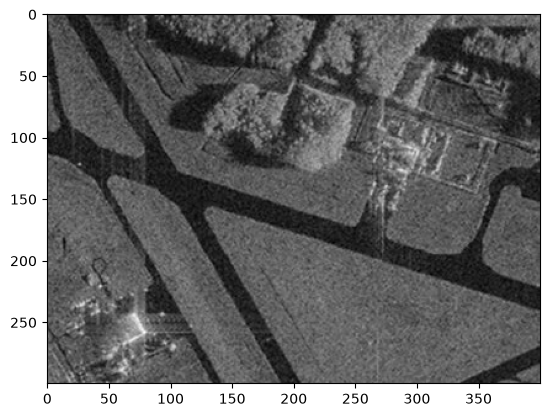

In [8]:
image_lawn = cv2.imread('sar_1.jpg')
image_lawn_gray = cv2.cvtColor(image_lawn, cv2.COLOR_BGR2GRAY)
plt.imshow(image_lawn_gray, cmap='gray')

In [9]:
import math
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])
                                                            
    if abs(av_val - img[point]) <= T:
        return True
    
    return False
    

In [10]:
def region_growing(image, seed_point, homo_fun, r, T):
    mask = np.zeros(image.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    kernel = np.ones((2*r + 1, 2*r + 1), np.uint8)
    while count > 0:
        neighbors = cv2.dilate(mask, kernel)
        candidates = np.argwhere((neighbors > 0) & (mask == 0))
        local_mask = np.zeros(image.shape, np.uint8)
        for i, j in candidates:
            if homo_fun(image, mask, (i, j), T):
                local_mask[i, j] = 1
        count = np.count_nonzero(local_mask)
        mask += local_mask

    return mask*255

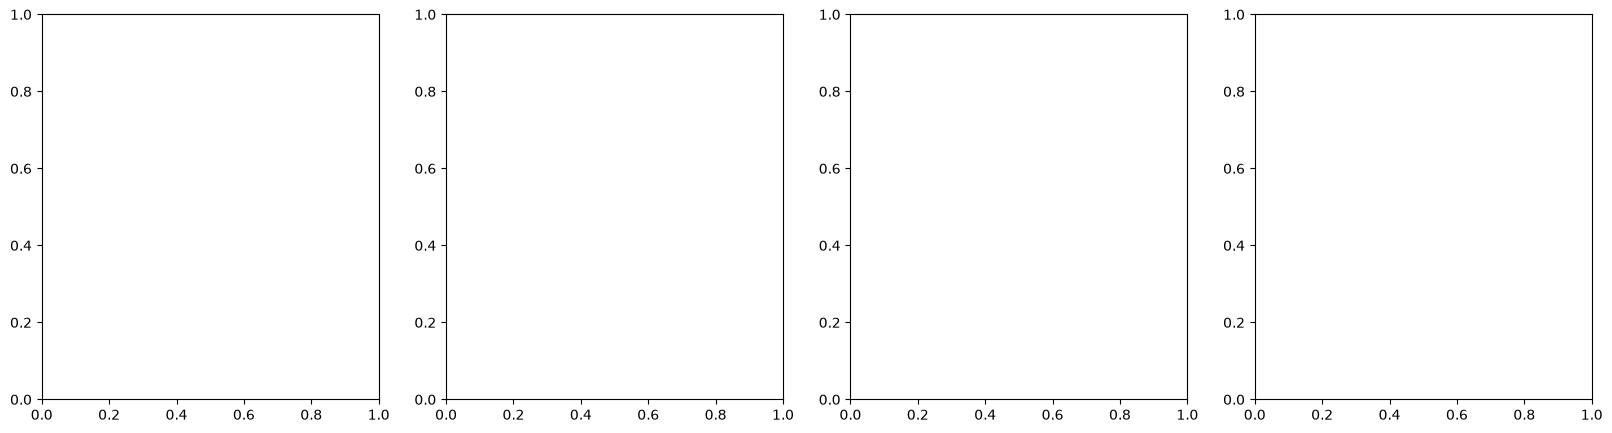

In [11]:
seed_point = (250, 250)
T_params = [5, 10, 15, 20]
fig, axs = plt.subplots(1, len(T_params), figsize=(20, 5))


In [12]:

for ax, T in zip(axs, T_params):
    mask_T = region_growing(image_lawn_gray, seed_point, homo_average, 1, T)
    ax.imshow(mask_T, cmap='gray')
    ax.set_title(f'T={T}, area={np.count_nonzero(mask_T)}')